# Week 5 - Part B: the five decisions, computed

Every answer here is a number or a small table printed by the code, not an opinion. The printed output of the script version is saved as `submission/partB_output.txt`.

All data is synthetic course data for CDB601220 (Week 5).

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_agg import FigureCanvasAgg
from scipy import stats
from scipy.optimize import brentq
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

try:
    ROOT = Path(__file__).resolve().parents[1]
    IN_NOTEBOOK = False
except NameError:
    ROOT = Path.cwd()
    IN_NOTEBOOK = True
sys.path.insert(0, str(ROOT))


def show():
    """Inline in the notebook; as a script just close the figure (the PNG is already saved)."""
    if IN_NOTEBOOK:
        plt.show()
    else:
        plt.close("all")


import geolib as gl
from vizlib import PALETTE, save_fig, style_defaults

DATA = ROOT / "data"
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
style_defaults()
warnings.filterwarnings("ignore", category=FutureWarning)
BLUE, ORANGE, GREEN = PALETTE["series"]
GREY, INK, SOFT = PALETTE["muted"], PALETTE["ink"], PALETTE["ink_soft"]
NUM = ["gdp_pc", "healthcare_access", "urban_pct", "median_age", "cases_per_100k"]


def src(file, extra=""):
    note = f"Source: synthetic course data, CDB601220 Week 5 ({file}). Chart: Syed Sami Ullah."
    return note + ("\n" + extra if extra else "")


hi = pd.read_csv(DATA / "health_indicators.csv")

## B1 · The size range for Part D1
`s` in `ax.scatter` is an **area** in points², so I keep it proportional to population: `s = lo × pop / min(pop)`. That makes `hi = 589 × lo` automatically, and the only free choice is `lo`. I test five values on the same 10 × 6 inch canvas Part D1 uses, and count how many marks end up with their centre underneath a bigger mark (drawn big-first, so the small ones still sit on top).

In [2]:
FIGSIZE_D1 = (10, 6)


def hidden_under_bigger(s):
    fig, ax = plt.subplots(figsize=FIGSIZE_D1)
    ax.scatter(hi.gdp_pc, hi.healthcare_access, s=s)
    ax.set_xscale("log")
    ax.set_ylim(0, 100)
    fig.canvas.draw()
    xy = ax.transData.transform(np.column_stack([hi.gdp_pc, hi.healthcare_access]))
    r = np.sqrt(np.asarray(s)) / 2 * fig.dpi / 72
    d = np.hypot(xy[:, None, 0] - xy[None, :, 0], xy[:, None, 1] - xy[None, :, 1])
    cov = (d < r[None, :]) & (r[None, :] > r[:, None])
    biggest = int(np.argmax(s))
    plt.close(fig)
    return int(cov.any(axis=1).sum()), int(cov[:, biggest].sum())


ratio = hi.pop_m.max() / hi.pop_m.min()
rows = []
for lo in [2, 4, 6, 10, 16]:
    s = lo * hi.pop_m / hi.pop_m.min()
    n_hid, n_big = hidden_under_bigger(s)
    rows.append({"lo (pt²)": lo, "hi (pt²)": round(s.max()), "smallest across (pt)": round(np.sqrt(lo), 2),
                 "largest across (pt)": round(np.sqrt(s.max()), 1), "centres under a bigger mark": n_hid,
                 "centres under the largest": n_big})
b1 = pd.DataFrame(rows)
print(f"population spans {ratio:.0f}x, so hi/lo = {ratio:.0f} in AREA and sqrt({ratio:.0f}) = {np.sqrt(ratio):.1f} in diameter\n")
print(b1.to_string(index=False))

population spans 589x, so hi/lo = 589 in AREA and sqrt(589) = 24.3 in diameter

 lo (pt²)  hi (pt²)  smallest across (pt)  largest across (pt)  centres under a bigger mark  centres under the largest
        2      1178                  1.41                 34.3                            6                          3
        4      2356                  2.00                 48.5                           12                          4
        6      3534                  2.45                 59.4                           19                          6
       10      5890                  3.16                 76.7                           26                          7
       16      9424                  4.00                 97.1                           37                         20


In [3]:
SIZES = (6.0, 6.0 * ratio)
s_d1 = SIZES[0] * hi.pop_m / hi.pop_m.min()
assert np.allclose(s_d1 / hi.pop_m, s_d1.iloc[0] / hi.pop_m.iloc[0])          # area proportional to population
assert np.isclose(s_d1.max() / s_d1.min(), ratio)                              # area ratio = data ratio
print(f"chosen sizes = ({SIZES[0]:g}, {SIZES[1]:,.0f}) pt²")
print(f"diameter ratio = sqrt({SIZES[1]:,.0f} / {SIZES[0]:g}) = {np.sqrt(SIZES[1] / SIZES[0]):.1f}x (area ratio {SIZES[1] / SIZES[0]:.0f}x = population ratio)")
print(f"if pop drove the RADIUS instead, the diameter ratio would be {ratio:.0f}x and the area ratio {ratio ** 2:,.0f}x")

chosen sizes = (6, 3,534) pt²
diameter ratio = sqrt(3,534 / 6) = 24.3x (area ratio 589x = population ratio)
if pop drove the RADIUS instead, the diameter ratio would be 589x and the area ratio 346,921x


**My choice: `sizes = (6, 3,534)` pt², area proportional to population.**
- **Low end:** 6 pt² is a dot 2.4 pt across, about the size of a full stop in 10-pt type. At 4 pt² (2 pt) the smallest countries start to disappear once they get a white edge, and at 2 pt² they're gone. So 6 is the smallest that still reads.
- **High end:** I don't get to pick it separately. Area must stay proportional, so it's 589 × 6 = 3,534 pt², a 59-pt circle (about 21 mm). Making the small end bigger (10 or 16) pushes Wessant to 77-95 pt across and buries more neighbours. At 6, 6 centres sit under Wessant itself (19 under some bigger mark), and because I draw big marks first with alpha 0.75, every one of those still shows on top.
- **Area, not radius:** `s/pop` is the same constant for all 60 countries (asserted above), so the area ratio is 589× and the diameter ratio is √589 = 24.3×. A radius encoding would have made it 589× across.

## B2 · Overplotting: the 800-point cluster at (3.1, 3.0)
Same 9,000 points four ways. I don't just eyeball "visible": I render each panel and measure how dark it is at the cluster centre, at the centre of the main cloud, and at the lightest point on the way from one to the other. Two questions: is the cluster a **separate blob** (darker than the dip by at least 1.25×), and does the picture show it as **denser than the core**, which it really is?

In [4]:
sd = pd.read_csv(DATA / "scatter_dense.csv")
ALPHA, GRIDSIZE = 0.04, 45
CL, CORE = np.array([3.1, 3.0]), sd[["x", "y"]].median().to_numpy()
d_cl = np.hypot(sd.x - CL[0], sd.y - CL[1])
print(f"{len(sd):,} points; within 0.5 of (3.1, 3.0): {(d_cl < 0.5).sum()}, within 1.0: {(d_cl < 1.0).sum()}")
kde = stats.gaussian_kde(sd[["x", "y"]].to_numpy().T)
gx, gy = np.meshgrid(np.linspace(-4, 4.5, 220), np.linspace(-4, 4.5, 220))
gz = kde(np.vstack([gx.ravel(), gy.ravel()])).reshape(gx.shape)


def draw(ax, how):
    if how == "opaque":
        ax.scatter(sd.x, sd.y, s=6, color=BLUE, linewidths=0)
    elif how == "transparent":
        ax.scatter(sd.x, sd.y, s=6, color=BLUE, alpha=ALPHA, linewidths=0)
    elif how == "hexbin":
        ax.hexbin(sd.x, sd.y, gridsize=GRIDSIZE, cmap=PALETTE["sequential"], mincnt=1, extent=(-4, 4.5, -4, 4.5))
    else:
        ax.contourf(gx, gy, gz, levels=12, cmap=PALETTE["sequential"])
    ax.set_xlim(-4, 4.5)
    ax.set_ylim(-4, 4.5)
    ax.set_aspect("equal")


def darkness_at(how):
    """Render one panel alone and read mean darkness (1 - luminance) around three spots."""
    fig = plt.figure(figsize=(4, 4), dpi=100)
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_axis_off()
    draw(ax, how)
    canvas = FigureCanvasAgg(fig)
    canvas.draw()
    img = np.asarray(canvas.buffer_rgba())[..., :3] / 255
    dark = 1 - img @ np.array([0.2126, 0.7152, 0.0722])
    px = ax.transData.transform(np.array([CL, CORE]))
    H = dark.shape[0]
    yy, xx = np.mgrid[0:H, 0:dark.shape[1]]
    unit = (ax.transData.transform([[1, 0]]) - ax.transData.transform([[0, 0]]))[0, 0]

    def disc(c, r0, r1):
        rr = np.hypot(xx - c[0], (H - yy) - c[1]) / unit
        return dark[(rr >= r0) & (rr < r1)].mean()

    path = [px[1] + t * (px[0] - px[1]) for t in np.linspace(0.3, 0.85, 12)]     # walk from the core to the cluster
    saddle = min(disc(p, 0, 0.12) for p in path)
    plt.close(fig)
    return disc(px[0], 0, 0.15), disc(px[1], 0, 0.15), saddle


b2 = []
for how in ["opaque", "transparent", "hexbin", "kde"]:
    c, core, saddle = darkness_at(how)
    b2.append({"method": how, "cluster": round(c, 2), "main core": round(core, 2), "dip between them": round(saddle, 2),
               "cluster / core": round(c / core, 2)})
b2 = pd.DataFrame(b2)
b2["separate blob"] = b2["cluster"] > 1.25 * b2["dip between them"]
true_ratio = (d_cl < 0.15).sum() / (np.hypot(sd.x - CORE[0], sd.y - CORE[1]) < 0.15).sum()
b2["shows it denser than core"] = b2["cluster / core"] > 1.1
print(f"TRUE density, points within 0.15: cluster {(d_cl < 0.15).sum()} vs core "
      f"{(np.hypot(sd.x - CORE[0], sd.y - CORE[1]) < 0.15).sum()} -> cluster is {true_ratio:.2f}x as dense as the core\n")
print(b2.to_string(index=False))

9,000 points; within 0.5 of (3.1, 3.0): 709, within 1.0: 800


TRUE density, points within 0.15: cluster 133 vs core 82 -> cluster is 1.62x as dense as the core

     method  cluster  main core  dip between them  cluster / core  separate blob  shows it denser than core
     opaque     0.63       0.63              0.00            1.00           True                      False
transparent     0.17       0.12              0.00            1.46           True                       True
     hexbin     0.74       0.47              0.00            1.58           True                       True
        kde     0.57       0.78              0.05            0.73           True                      False


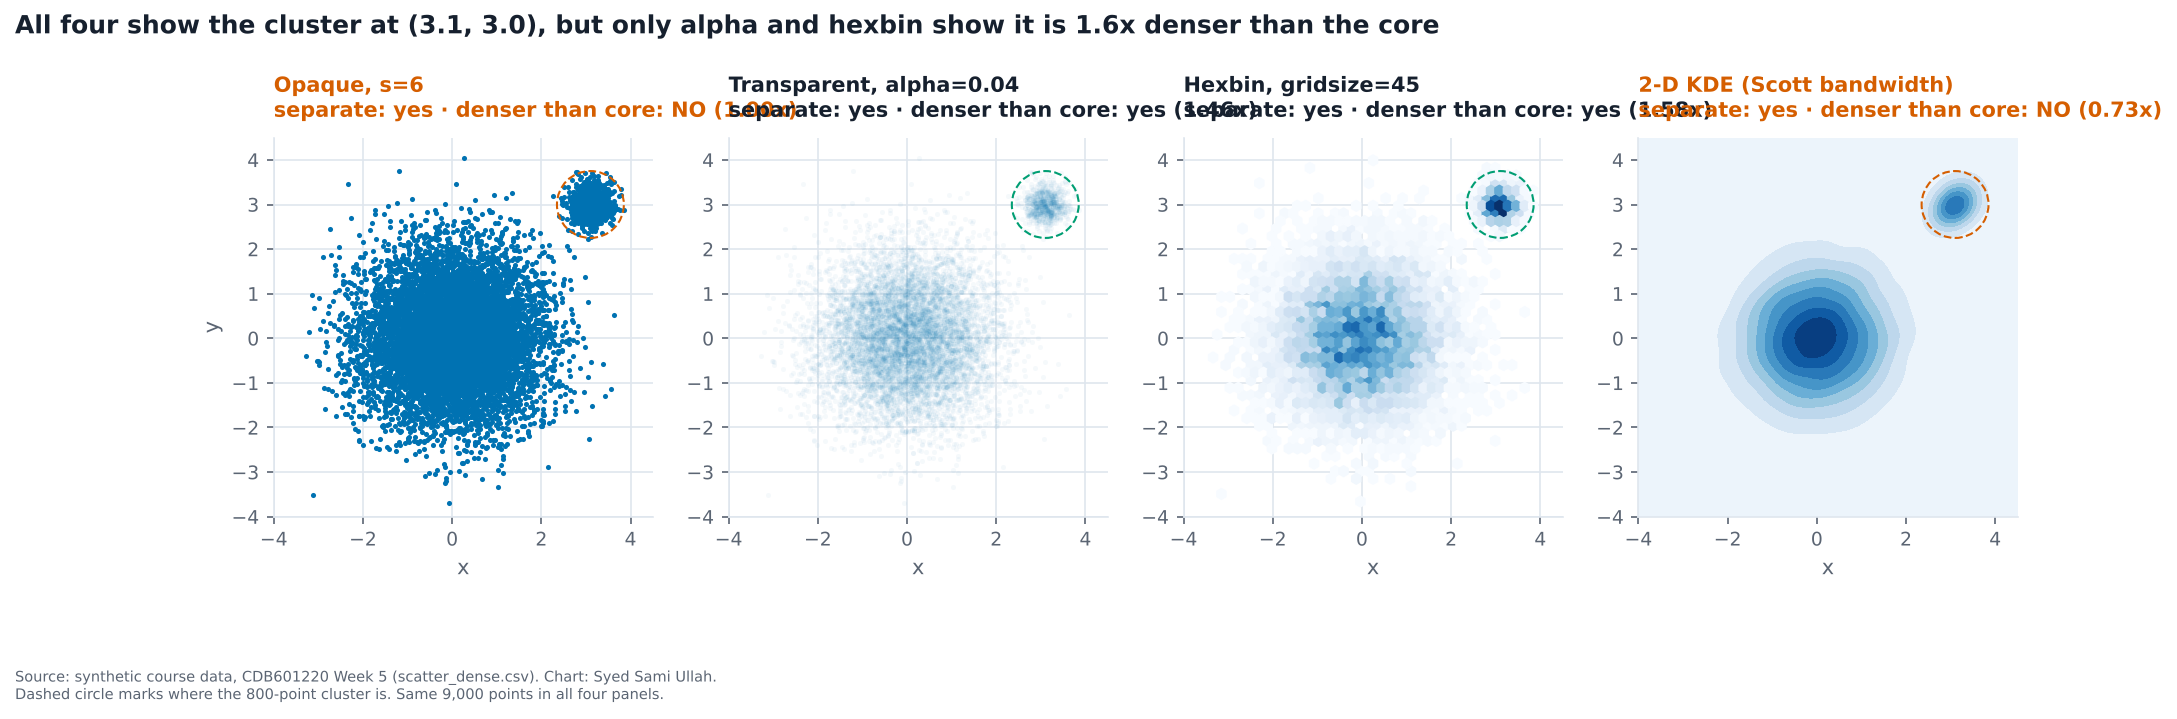

In [5]:
fig, axs = plt.subplots(1, 4, figsize=(15, 4.3))
titles = {"opaque": "Opaque, s=6", "transparent": f"Transparent, alpha={ALPHA}",
          "hexbin": f"Hexbin, gridsize={GRIDSIZE}", "kde": "2-D KDE (Scott bandwidth)"}
for ax, how in zip(axs, titles):
    draw(ax, how)
    row = b2.set_index("method").loc[how]
    ok = bool(row["shows it denser than core"])
    ax.set_title(f"{titles[how]}\nseparate: yes · denser than core: {'yes' if ok else 'NO'} ({row['cluster / core']:.2f}x)",
                 fontsize=10, color=INK if ok else ORANGE)
    ax.add_patch(plt.Circle(CL, 0.75, fill=False, ls="--", color=ORANGE if not ok else GREEN, lw=1))
    ax.set_xlabel("x")
axs[0].set_ylabel("y")
fig.suptitle(f"All four show the cluster at (3.1, 3.0), but only alpha and hexbin show it is {true_ratio:.1f}x denser than the core",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
save_fig(fig, CHARTS / "partB_q2_overplotting.png", note=src("scatter_dense.csv", "Dashed circle marks where the 800-point cluster is. Same 9,000 points in all four panels."))
show()

**What this chart shows.** The cluster sits apart from the main cloud, so all four show *something* there. The difference is what they say about its weight. The opaque scatter paints it exactly as dark as the core (1.00×), so you can't tell it's 800 points packed tighter than anything else. The KDE smooths it into a weaker bump (0.73×), which actually reverses the truth. Alpha and hexbin show it darker than the core (1.46× and 1.58×), which matches the real density (1.62× by point count within 0.15 of each centre).

**What I would publish:** the **hexbin** (gridsize 45). It shows the cluster as the darkest cells, it keeps real counts (a colourbar in points per hexagon that a reader can quote), and unlike the KDE it doesn't depend on a smoothing bandwidth I'd have to defend, and it doesn't flip the order of the two peaks. Transparency also works, but the result depends on alpha *and* marker size, and at alpha 0.04 the outlying single points almost vanish. Declared parameters: `alpha = 0.04`, `gridsize = 45`, KDE bandwidth = Scott's rule.

## B3 · Scaling and dimension reduction

In [6]:
g = hi.gdp_pc
second = g.nlargest(2).iloc[1]
out = []
for how in ["minmax", "zscore", "rank"]:
    S = gl.scale_frame(hi, NUM, how)["gdp_pc"]
    others = S[hi.gdp_pc < g.max()]
    out.append({"scaling": how, "Aldonia": round(S.max(), 3), "2nd richest": round(S[g == second].iloc[0], 3),
                "median": round(S.median(), 3), "other 59 span": f"{others.min():.3f} to {others.max():.3f}",
                "share of axis used by other 59": f"{(others.max() - others.min()) / (S.max() - S.min()):.1%}"})
print(pd.DataFrame(out).to_string(index=False))

scaling  Aldonia  2nd richest  median   other 59 span share of axis used by other 59
 minmax    1.000        0.106   0.017  0.000 to 0.106                          10.6%
 zscore    7.501        0.473  -0.225 -0.362 to 0.473                          10.6%
   rank    1.000        0.983   0.508  0.017 to 0.983                          98.3%


In [7]:
Z = StandardScaler().fit_transform(hi[NUM])
pca = PCA().fit(Z)
evr = pca.explained_variance_ratio_
print("explained variance ratio:", np.round(evr, 3).tolist())
print(f"first two components: {evr[0]:.1%} + {evr[1]:.1%} = {evr[:2].sum():.1%}  -> a 2-axis picture misses {1 - evr[:2].sum():.1%}")
print("PC1 loadings:", {k: round(float(v), 2) for k, v in zip(NUM, pca.components_[0])})
print("PC2 loadings:", {k: round(float(v), 2) for k, v in zip(NUM, pca.components_[1])})
Zl = StandardScaler().fit_transform(hi.assign(gdp_pc=np.log10(hi.gdp_pc))[NUM])
evr_l = PCA().fit(Zl).explained_variance_ratio_
print(f"(with log10 gdp first: PC1+PC2 = {evr_l[:2].sum():.1%}, PC2 alone {evr_l[1]:.1%})")

explained variance ratio: [0.675, 0.162, 0.077, 0.065, 0.022]
first two components: 67.5% + 16.2% = 83.7%  -> a 2-axis picture misses 16.3%
PC1 loadings: {'gdp_pc': 0.32, 'healthcare_access': 0.51, 'urban_pct': 0.46, 'median_age': 0.45, 'cases_per_100k': -0.47}
PC2 loadings: {'gdp_pc': 0.87, 'healthcare_access': -0.25, 'urban_pct': -0.07, 'median_age': -0.4, 'cases_per_100k': -0.13}
(with log10 gdp first: PC1+PC2 = 87.3%, PC2 alone 8.6%)


- **Min-max:** Aldonia sits at 1.000 and the other 59 are squeezed into 0.000-0.106, the bottom 11% of the axis (median 0.017). It throws away the shape of the other 59.
- **Z-score:** Aldonia lands at z = +7.50 and the rest sit between −0.36 and +0.47, so they still use only 11% of the axis. It keeps the relative gaps, but the outlier still decides the range.
- **Percentile rank:** the 60 are evenly spaced from 0.017 to 1.000, and Aldonia is just one step (1/60) above the second richest. Immune to the outlier, but the 9.2× gap is gone completely.
- **PCA:** on the five standardised columns, PC1 explains 67.5% and PC2 16.2%, together 83.7%. A two-axis picture of this data misses **16.3%** of the variance. PC1 is a general "development" axis (access, urban, median age up, cases down), and PC2 is mostly GDP on its own because of the outlier. With log GDP the first two reach 87.3%, but PC2 drops to 8.6%, so the second axis says very little.

## B4 · Project before you measure

In [8]:
feats = gl.read_geojson(DATA / "districts.geojson")
dh = pd.read_csv(DATA / "district_health.csv").set_index("code")


def shoelace(x, y):
    x, y = np.asarray(x), np.asarray(y)
    return 0.5 * abs(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1)))


codes = [f["code"] for f in feats]
A = pd.DataFrame({"sphere_km2": [gl.polygon_area_km2(f["ring"]) for f in feats],
                  "degrees_sq": [shoelace(*zip(*f["ring"])) for f in feats],
                  "mercator_km2": [shoelace(*gl.mercator_xy(*zip(*f["ring"]))) for f in feats]}, index=codes)
A["lat"] = dh.loc[codes, "lat"]
A["share_sphere"] = A.sphere_km2 / A.sphere_km2.sum()
A["share_degrees"] = A.degrees_sq / A.degrees_sq.sum()
A["distortion"] = A.share_degrees / A.share_sphere
A["mercator_inflation"] = A.mercator_km2 / A.sphere_km2
assert np.allclose(A.sphere_km2, dh.loc[codes, "area_km2"], rtol=1e-4)
north4 = A.nlargest(4, "lat").index.tolist()
print(f"four northernmost (by vertex-mean latitude): {north4}")
print(f"their share of the total area: spherical {A.loc[north4, 'share_sphere'].sum():.2%}, degree shoelace {A.loc[north4, 'share_degrees'].sum():.2%} "
      f"({A.loc[north4, 'share_degrees'].sum() / A.loc[north4, 'share_sphere'].sum() - 1:+.1%})")
worst = (A.distortion - 1).abs().idxmax()
print(f"most distorted single district: {worst} ({A.loc[worst, 'share_sphere']:.2%} -> {A.loc[worst, 'share_degrees']:.2%}, x{A.loc[worst, 'distortion']:.3f}); "
      f"most shrunk: {A.distortion.idxmin()} (x{A.distortion.min():.3f})")
print(f"Mercator area inflation, measured on the projected polygons: {A.mercator_inflation.min():.2f}x ({A.mercator_inflation.idxmin()}) "
      f"to {A.mercator_inflation.max():.2f}x ({A.mercator_inflation.idxmax()}); north vs south {A.mercator_inflation.max() / A.mercator_inflation.min():.2f}x")
print(f"check: sec^2(latitude) at the district centres runs {(1 / np.cos(np.radians(A.lat)) ** 2).min():.2f} to {(1 / np.cos(np.radians(A.lat)) ** 2).max():.2f}")
print(A[["lat", "share_sphere", "share_degrees", "distortion", "mercator_inflation"]].round(4).sort_values("lat").to_string())

four northernmost (by vertex-mean latitude): ['D21', 'D22', 'D19', 'D24']
their share of the total area: spherical 10.51%, degree shoelace 11.08% (+5.5%)
most distorted single district: D21 (2.15% -> 2.27%, x1.056); most shrunk: D02 (x0.962)
Mercator area inflation, measured on the projected polygons: 1.24x (D02) to 1.49x (D21); north vs south 1.21x
check: sec^2(latitude) at the district centres runs 1.24 to 1.49
         lat  share_sphere  share_degrees  distortion  mercator_inflation
D02  25.9456        0.0902         0.0867      0.9616              1.2374
D03  26.0302        0.0449         0.0432      0.9623              1.2395
D01  26.0446        0.0367         0.0353      0.9624              1.2396
D05  26.0703        0.0440         0.0423      0.9625              1.2399
D04  26.0712        0.0932         0.0898      0.9626              1.2402
D06  26.1221        0.0438         0.0422      0.9631              1.2413
D11  29.0466        0.0184         0.0182      0.9886            

- The four northernmost districts (D21, D22, D19, D24) hold **10.51%** of the land measured on the sphere but **11.08%** by a shoelace on raw degrees, which overstates them by 5.5%. The single most distorted district is **D21**, at ×1.056. Its share goes from 2.15% to 2.27%. Southern districts shrink by about 3.7% to make up for it.
- **Mercator inflates area by 1.24× in the south to 1.49× in the north**, so a northern district is drawn about 20% bigger, relative to a southern one, than it really is. On a choropleth the area of each patch *is* the amount of colour the reader sees, so a projection that inflates the north by 20% adds 20% more ink to whatever class the north is in. That's why slide 34 asks for an equal-area projection.
- A note on the toolkit: `python geolib.py` prints Mercator inflation as "1.144x south .. 1.168x north". That line divides by cos(latitude) once, but Mercator stretches **both** x and y by sec(latitude), so area goes as sec². Measured on the projected polygons the factor is 1.24 to 1.49, which matches sec² at the district centres. I'm using my measured numbers.

## B5 · Small-area stability: the funnel

In [9]:
s6 = pd.read_csv(DATA / "smallarea_cases.csv")
s6["rate"] = s6.cases / s6.population * 1e5
pool = s6.cases.sum() / s6.population.sum() * 1e5
fl = gl.funnel_limits(s6.population, pool)
lam = pool / 1e5 * s6.population
s6["lo95"] = np.maximum(lam - 1.96 * np.sqrt(lam), 0) / s6.population * 1e5
s6["hi95"] = (lam + 1.96 * np.sqrt(lam)) / s6.population * 1e5
outside = s6[(s6.rate < s6.lo95) | (s6.rate > s6.hi95)]
print(f"pooled rate {pool:.2f} per 100k; outside the 95% limits: {len(outside)} of 40 -> {outside.unit.tolist()}")
print(f"expected outside by chance alone (5% of 40): {0.05 * 40:.0f}")
assert np.allclose(s6.sort_values("population").hi95.to_numpy(), fl.hi.to_numpy())     # same limits as the toolkit


def upper95(p, base):
    lam_ = base / 1e5 * p
    return (lam_ + 1.96 * np.sqrt(lam_)) / p * 1e5


def lower95(p, base):
    lam_ = base / 1e5 * p
    return (lam_ - 1.96 * np.sqrt(lam_)) / p * 1e5


p_funnel = brentq(lambda p: upper95(p, 9) - 18, 1e3, 1e7)
p_both = brentq(lambda p: upper95(p, 9) - lower95(p, 18), 1e3, 1e7)
print(f"population where the 95% funnel around 9/100k no longer reaches 18/100k: {p_funnel:,.0f}")
print(f"population where the 95% bands around 9 and around 18 stop overlapping: {p_both:,.0f}")

pooled rate 8.72 per 100k; outside the 95% limits: 1 of 40 -> ['U32']
expected outside by chance alone (5% of 40): 2
population where the 95% funnel around 9/100k no longer reaches 18/100k: 42,684
population where the 95% bands around 9 and around 18 stop overlapping: 248,783


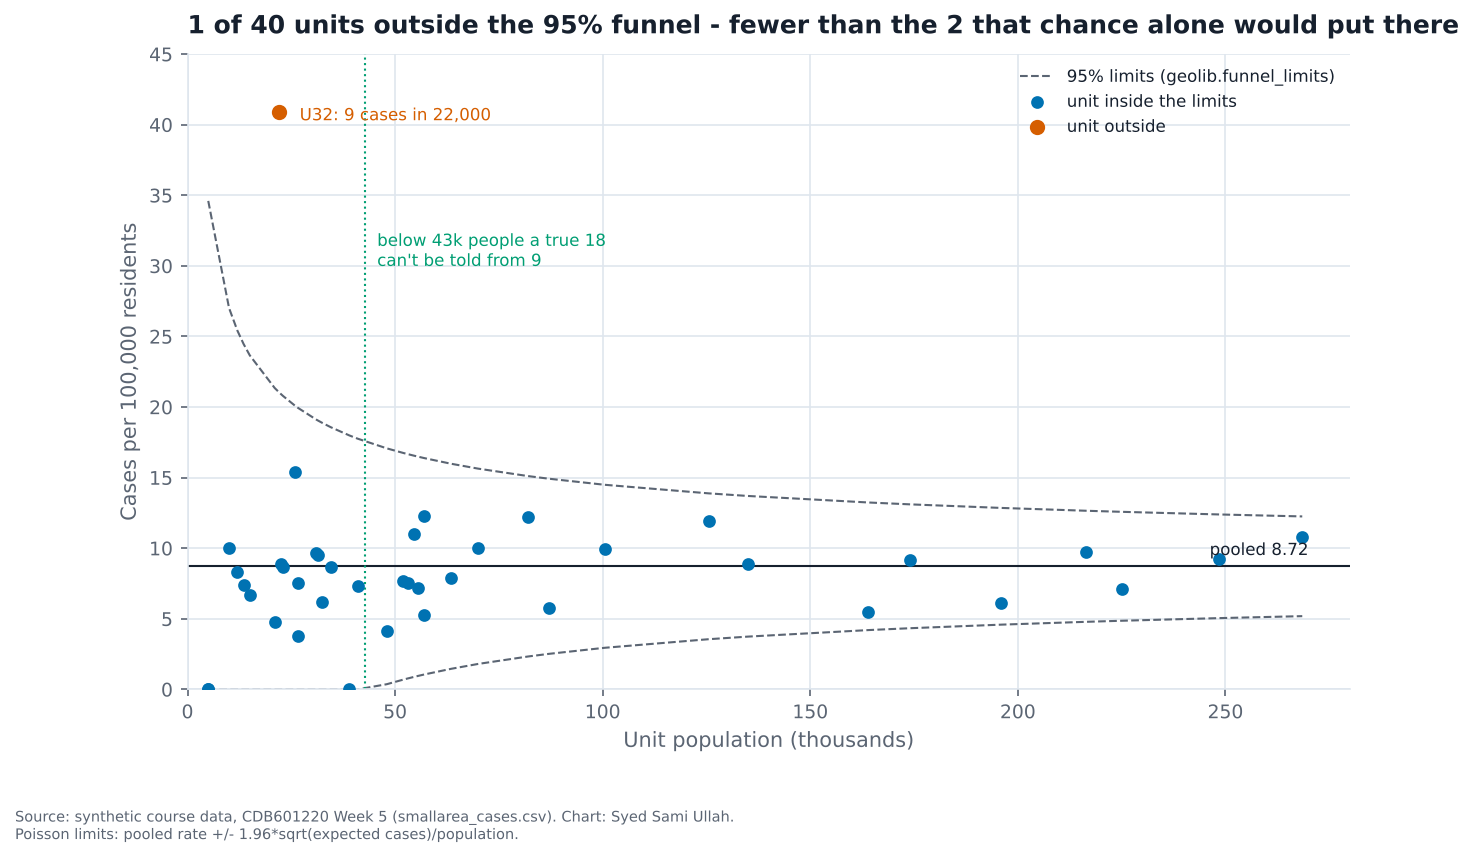

In [10]:
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(fl.population / 1e3, fl.hi, color=SOFT, ls="--", lw=1, label="95% limits (geolib.funnel_limits)")
ax.plot(fl.population / 1e3, fl.lo, color=SOFT, ls="--", lw=1)
ax.axhline(pool, color=INK, lw=1)
inside = ~s6.unit.isin(outside.unit)
ax.scatter(s6.population[inside] / 1e3, s6.rate[inside], s=26, color=BLUE, zorder=3, label="unit inside the limits")
ax.scatter(outside.population / 1e3, outside.rate, s=40, color=ORANGE, zorder=4, label="unit outside")
for _, rr in outside.iterrows():
    ax.annotate(f"{rr.unit}: {rr.cases:.0f} cases in {rr.population:,.0f}", (rr.population / 1e3, rr.rate), xytext=(10, -4),
                textcoords="offset points", fontsize=8, color=ORANGE)
ax.axvline(p_funnel / 1e3, color=GREEN, lw=1, ls=":")
ax.text(p_funnel / 1e3 + 3, 30, f"below {p_funnel / 1e3:,.0f}k people a true 18\ncan't be told from 9", fontsize=8, color=GREEN)
ax.text(270, pool + 0.8, f"pooled {pool:.2f}", ha="right", fontsize=8, color=INK)
ax.set_xlim(0, 280)
ax.set_ylim(0, 45)
ax.set_xlabel("Unit population (thousands)")
ax.set_ylabel("Cases per 100,000 residents")
ax.legend(loc="upper right", fontsize=8)
ax.set_title(f"{len(outside)} of 40 units outside the 95% funnel - fewer than the 2 that chance alone would put there")
save_fig(fig, CHARTS / "partB_q5_funnel.png", note=src("smallarea_cases.csv", "Poisson limits: pooled rate +/- 1.96*sqrt(expected cases)/population."))
show()

**What this chart shows.** The rates fan out as population falls, exactly the funnel shape. Only U32 sits outside, at the narrow-population end.

- **Outside the limits: 1 of 40** (U32). With 95% limits, chance alone puts about 2 of 40 outside, so the map in case 6 is what noise looks like. Its "hotspot" and its three zero-rate units are the small units at the two ends of a funnel, not places. (U32 is further out than most noise, p ≈ 0.007 after allowing for 40 units, so I'd check its records before ignoring it. But nine cases can't carry a "five times the national rate" headline.)
- **Minimum population to tell 9 from 18 per 100,000:** about **42,700** people. Below that, a unit whose true rate is 18 still falls inside the 95% funnel around 9. That's the bare minimum. For both 95% bands to stop overlapping, so you could tell them apart in either direction, it takes about **249,000**, and only one of the 40 units (268,500) is that big.